# 04 – Dự báo nhiệt độ cho mức L2 (Giai đoạn 4, mục 4.0)

**Vì sao cần.** Mức L2 dùng nhiệt độ **dự báo** cho ngày D. GEFCom2012 không có dữ liệu dự báo thời tiết lịch sử, nên em tự xây một mô hình dự báo nhiệt độ 24 giờ đơn giản. Ràng buộc: dự báo cho ngày D chỉ được dùng nhiệt độ đến 23:00 ngày D−1.

**Ba phương án** (code ở `src/temperature.py`):

| Phương án | Công thức |
|---|---|
| persistence | T̂(D,h) = T(D−1,h) |
| climatology | trung bình T cùng giờ, ±7 ngày quanh cùng ngày ở 1–3 năm trước |
| regression | với mỗi giờ h: T̂(D,h) = a + b·T(D−1,h) + c·T(D−1,23:00) + d·clim(D,h), fit lại đầu mỗi tháng |

Chọn phương án có MAE nhỏ nhất **trên validation**, rồi dùng cho cả validation và test.

In [1]:
import sys
sys.path.append("..")          # để import được thư mục src/ khi notebook nằm trong notebooks/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)
plt.rcParams["figure.figsize"] = (11, 3.5)

from src.data import load_dataset, PROCESSED
from src.evaluation import VAL_START, VAL_END, TEST_START, TEST_END
from src.temperature import build_temp_forecast, evaluate_methods

df = load_dataset("system")
temp_fc, table_val, best, fcs = build_temp_forecast(df)
table_test = evaluate_methods(fcs, TEST_START, TEST_END)
out = pd.concat({"validation": table_val, "test": table_test}, axis=1).round(2)
out.to_csv("../results/tables/4_0_du_bao_nhiet_do.csv")
print("Phương án được chọn:", best)
out

Phương án được chọn: regression


validation                     test                   
                 MAE_F MAE_F_gio_xau_nhat MAE_F MAE_F_gio_xau_nhat
regression        3.78               5.43  3.81               5.53
persistence       5.72               6.36  5.82               6.64
climatology       6.96               7.82  6.40               6.83

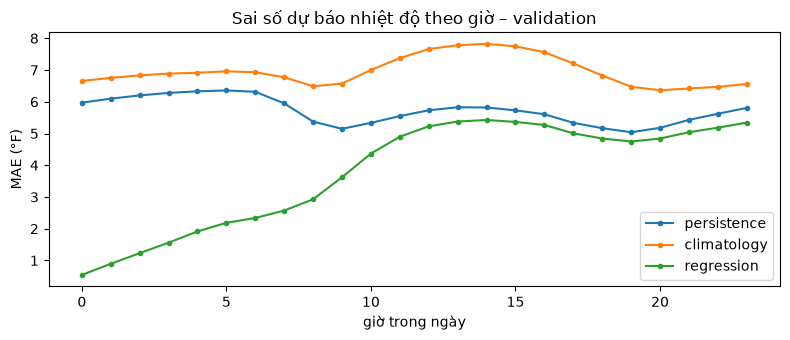

In [2]:
fig, ax = plt.subplots(figsize=(8, 3.5))
act = fcs["actual"].loc[VAL_START:VAL_END]
for name in ("persistence", "climatology", "regression"):
    (fcs[name].loc[VAL_START:VAL_END] - act).abs().mean().plot(ax=ax, marker="o", ms=3, label=name)
ax.set_xlabel("giờ trong ngày"); ax.set_ylabel("MAE (°F)"); ax.set_title("Sai số dự báo nhiệt độ theo giờ – validation")
ax.legend(); plt.tight_layout()
plt.savefig("../results/figures/4_0_mae_nhiet_do_theo_gio.png", dpi=120); plt.show()

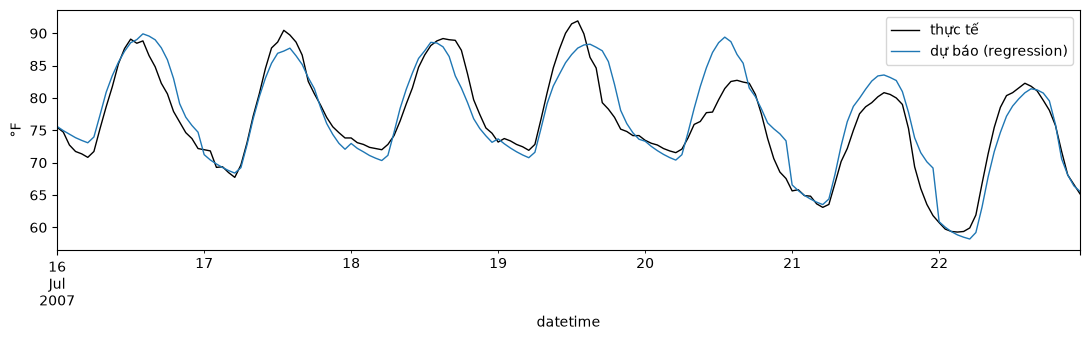

In [3]:
# Một tuần mùa hè để nhìn trực quan
w = slice("2007-07-16", "2007-07-22 23:00")
ax = df.loc[w, "T"].plot(label="thực tế", color="k", lw=1)
temp_fc.loc[w, "T_fc"].plot(ax=ax, label=f"dự báo ({best})", lw=1)
ax.set_ylabel("°F"); ax.legend(); plt.tight_layout(); plt.show()

In [4]:
temp_fc.to_parquet(PROCESSED / "temp_forecast_system.parquet")
print("đã lưu", temp_fc.shape)

đã lưu (39600, 1)


## Nhận xét

- **Regression tốt nhất:** MAE khoảng 3,8 °F trên cả validation và test, so với 5,7–5,8 °F của persistence. Kết quả ổn định giữa hai giai đoạn, nên phương án chọn trên validation không bị quá khớp.
- **Sai số tăng dần theo giờ trong ngày:** giờ càng xa origin, thông tin hôm trước càng ít giá trị.
- **Đây là mô hình nhiệt độ đơn giản.** Dự báo thời tiết thật (NWP) thường tốt hơn nhiều. Vì vậy L2 ở đây là cận **dưới** của trường hợp có dự báo thời tiết; thực tế sẽ nằm giữa L2 và L3. Em sẽ ghi điểm này vào phần hạn chế.
- **Khi fit, các mô hình ở L2 vẫn học trên nhiệt độ thật của quá khứ;** chỉ khi dự báo mới thay bằng nhiệt độ dự báo. Đây là cách làm thông dụng (ex-ante forecasting).